In [1]:
import numpy,pandas,json,scipy,sys
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess

sys.path.append("../../code/utility")
from load_data import load_cadmium,split_data_by_site,load_carbon

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600

In [2]:
# Load in data
## Data
data_directory = "../../data/"
d114cd_data = load_cadmium(data_directory)
svalbard_cd_data, arctic_cd_data, northsea_cd_data, kheu_cd_data = split_data_by_site(d114cd_data)

d13c_data = load_carbon(data_directory)
svalbard_c_data, arctic_c_data, northsea_c_data, kheu_c_data = split_data_by_site(d13c_data)

# Load in GP
d114dcd_gp = GaussianProcess().fromJSON(data_directory+"/output/d114cd_gp.json")
d13C_gp = GaussianProcess().fromJSON(data_directory+"/output/d13c_gp.json")

# Load in prior_results
with open(data_directory+"/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)
# Load in posterior_results
with open(data_directory+"/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_posterior_metrics.xlsx")

timestep = prior_metrics["time"].values[0]-prior_metrics["time"].values[1]


39999.99999999915


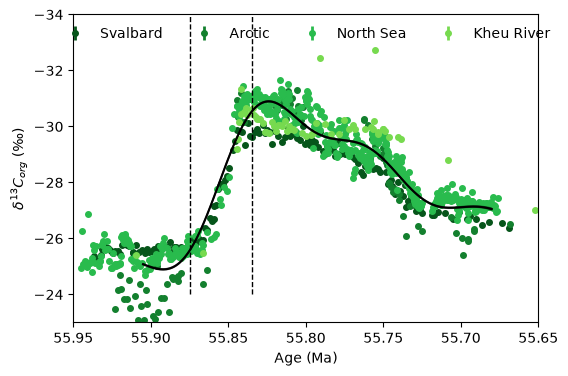

In [3]:
# Plot
figure,axis = pyplot.subplots(nrows=1,figsize=(6,4))
axes = [axis]
common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}

handle_0 = axes[0].errorbar(svalbard_c_data["Age model"],svalbard_c_data["δ13Corg(‰)"],yerr=0,color="#06551A",ecolor="#06551A",**common_attributes)
handle_1 = axes[0].errorbar(arctic_c_data["Age model"],arctic_c_data["δ13Corg(‰)"],yerr=0,color="#13802E",ecolor="#13802E",**common_attributes)
handle_2 = axes[0].errorbar(northsea_c_data["Age model"],northsea_c_data["δ13Corg(‰)"],yerr=0,color="#29BB4D",ecolor="#29BB4D",**common_attributes)
handle_3 = axes[0].errorbar(kheu_c_data["Age model"],kheu_c_data["δ13Corg(‰)"],yerr=0,color="#77DA4F",ecolor="#77DA4F",**common_attributes)

d13C_gp.plotMean(group=-1,color="black",axis=axes[0])
d13C_gp.plotArea(group=-1,color="black",alpha=0.5,set_axes=False,axis=axes[0])

axes[0].set_ylabel("$\\delta^{13}$C$_{org}$ (‰)")
axes[0].set_ylim((-23,-34))

axes[0].legend([handle_0,handle_1,handle_2,handle_3],
               ["Svalbard","Arctic","North Sea","Kheu River"],
               ncols=4,loc="upper center",frameon=False)

axes[0].set_xlim((55.95,55.65))

axes[0].set_xlabel("Age (Ma)")
axes[0].set_ylabel("$\\delta^{13}C_{org}$ (‰)")

axes[0].plot([55.875,55.875], [-24,-34],color="black",linestyle="--",linewidth=1)
axes[0].plot([55.835,55.835], [-24,-34],color="black",linestyle="--",linewidth=1)

print((55.875-55.835)*1e6)

pyplot.show()
# figure.savefig("../../figures/d13c.png",dpi=600)